# PhyVision: human physique classification with fitness guidance

**Created and authored by Swayam Shakya** · Version 5.1 · MIT License

PhyVision classifies a full-body photo of a person into one of four physique classes, **Athletic, Normal, Obese or Skinny**, and returns a fitness guide written for that class. It is the rebuilt, advanced version of the COSC-4427 *Human Physique Identifier* (v4.0), whose original notebook is kept in `legacy/`.

What changed from v4.0:

| | v4.0 | PhyVision 5.1 |
|---|---|---|
| Dataset | 50 photos (35 train / 7 val / 8 test) | 16,000 AI-generated people (2,000 train, 1,000 val, 1,000 test per class) in many poses and photo framings, each with an exact mask |
| Input to the model | Raw RGB photo | Normalised body silhouette plus a 100-number shape profile |
| Model | ResNet-18 with only the final layer trained | PhyNet: ResNet-18 silhouette branch fused with a shape-profile MLP, plus a framing head, trained end to end in two stages |
| Robustness | none | Segmentation-error augmentation; rembg / GrabCut / alpha background removal |
| Output | class label | class, probabilities, detected framing, photo check, proportion estimates, fitness guide |
| Interface | Colab cells | Web app (`python app.py`) with a control center, analyzer, photo guide and fitness guide library |

This notebook walks through the whole pipeline. It loads the trained model that ships with the project; set `TRAIN = True` below to retrain from scratch.

## 1. Setup

In [1]:
import os, sys, json
from pathlib import Path

# Works when run from notebooks/, from the project root, or in Google Colab
# (in Colab: upload PhyVision.zip to the session first; it is unzipped automatically).
if Path('/content').exists() and not Path('/content/PhyVision').exists() and Path('/content/PhyVision.zip').exists():
    import zipfile; zipfile.ZipFile('/content/PhyVision.zip').extractall('/content')
for cand in [Path.cwd(), Path.cwd().parent, Path('/content/PhyVision')]:
    if (cand / 'src' / 'phyvision').exists():
        ROOT = cand.resolve(); break
else:
    raise FileNotFoundError('Run this notebook from inside the PhyVision project folder.')
sys.path.insert(0, str(ROOT / 'src'))
os.chdir(ROOT)

import numpy as np, cv2, torch, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from phyvision import config
from phyvision.config import CLASSES, CLASS_LABELS
print('PhyVision', config.VERSION, 'by', config.AUTHOR)
print('Project folder:', ROOT.name)
print('torch', torch.__version__, '| device:', 'cuda' if torch.cuda.is_available() else 'cpu')

TRAIN = False            # set True to retrain PhyNet, both stages (a few hours on a laptop CPU, much faster on a GPU)
REGENERATE_DATA = False  # set True to rebuild the 16,000-image dataset

PhyVision 5.1.0 by Swayam Shakya
Project folder: PhyVision
torch 2.14.1+cu130 | device: cpu


## 2. The dataset

Real labelled photos of thousands of people per body type, with permission to redistribute, are not available, and scraping people's photos raises consent problems. PhyVision therefore uses an **AI-generated (procedurally rendered) dataset**. `src/phyvision/synth.py` models a person as anatomical widths and lengths measured as fractions of body height (shoulders, chest, waist, belly, hips, neck, upper arms, forearms, thighs, calves). Each class samples those from its own distribution, with deliberate overlap at the borders. The renderer then randomises sex, skin tone, hair, clothing type and colour, looseness of fit, arm pose (arms down or out, hands on hips, hand in pocket, bicep flex, raised arm), a slight body turn, the photo framing (head to feet, knees, mid-thigh or waist), the aspect ratio, background scene (including plain stock-photo backdrops), faint watermarks, lighting, camera roll, blur and sensor noise.

*AI assistance:* the dataset generator was built with help from Claude, an AI model by Anthropic, as a learning aid.

Because every body is generated from known numbers, each image has an exact label and a pixel-perfect segmentation mask. Train, validation and test people come from separate random seeds.

In [2]:
if REGENERATE_DATA:
    import subprocess
    subprocess.run([sys.executable, 'scripts/generate_dataset.py'], check=True)

import pandas as pd
counts = {s: {CLASS_LABELS[c]: len(list((config.DATA_DIR / s / c).glob('*.jpg'))) for c in CLASSES} for s in ('train', 'val', 'test')}
df = pd.DataFrame(counts); df.loc['Total'] = df.sum()
df['all splits'] = df.sum(axis=1)
df

,train,val,test,all splits
Athletic,2000,1000,1000,4000
Normal,2000,1000,1000,4000
Obese,2000,1000,1000,4000
Skinny,2000,1000,1000,4000
Total,8000,4000,4000,16000


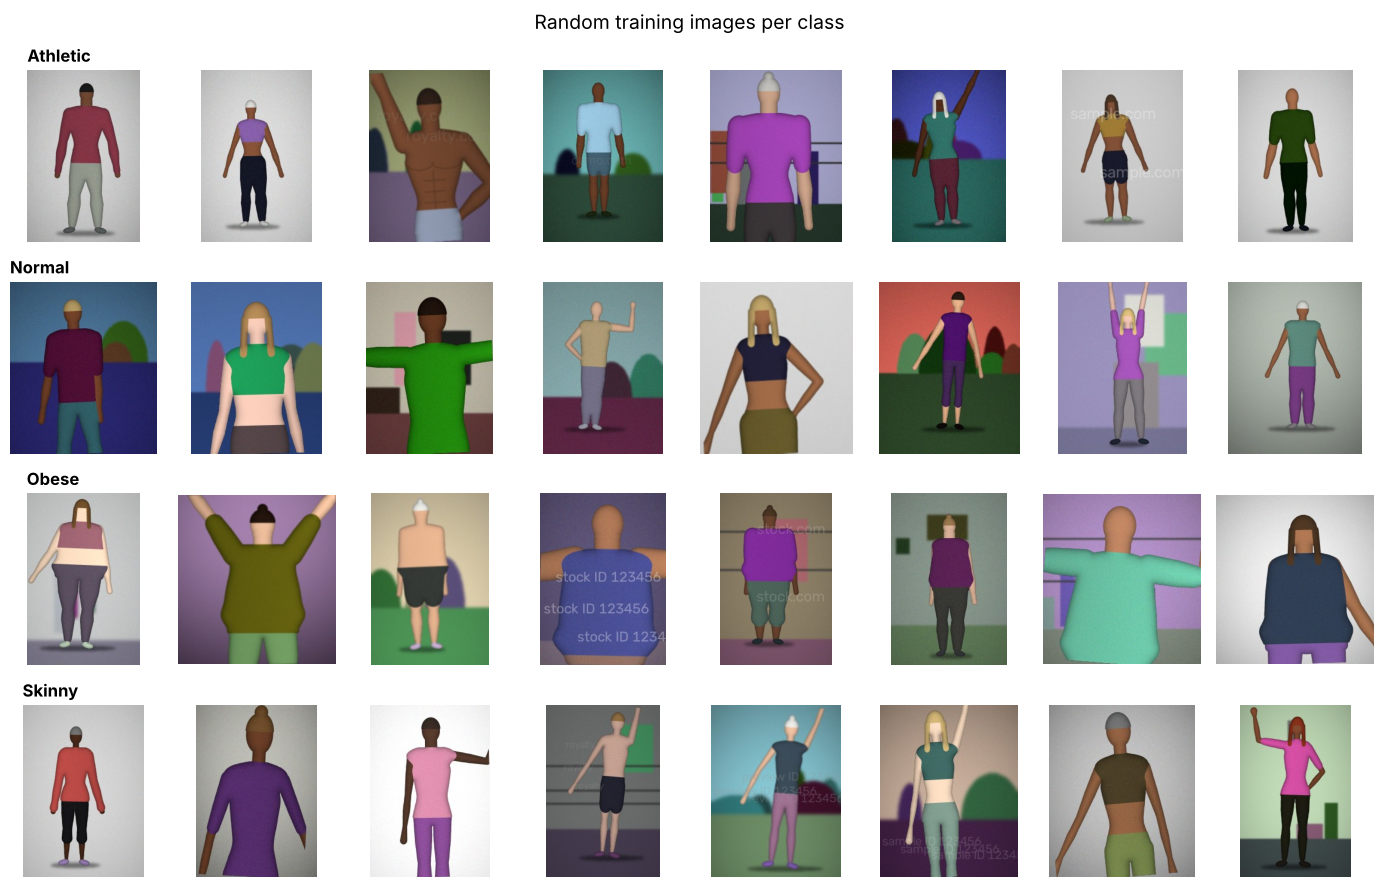

In [3]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(4, 8, figsize=(14, 9))
for r, c in enumerate(CLASSES):
    files = sorted((config.DATA_DIR / 'train' / c).glob('*.jpg'))
    for k, f in enumerate(rng.choice(files, 8, replace=False)):
        ax = axes[r, k]; ax.imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); ax.axis('off')
        if k == 0: ax.set_title(CLASS_LABELS[c], loc='left', fontsize=12, fontweight='bold')
plt.suptitle('Random training images per class', fontsize=14); plt.tight_layout(); plt.show()

shoulder_waist_ratio                                            \
                        count  mean   std   min   25%   50%   75%   max   
label                                                                     
athletic               2000.0  1.78  0.10  1.50  1.71  1.78  1.84  2.19   
normal                 2000.0  1.50  0.08  1.23  1.44  1.50  1.55  1.83   
obese                  2000.0  1.09  0.08  0.89  1.04  1.08  1.14  1.41   
skinny                 2000.0  1.66  0.09  1.34  1.60  1.66  1.72  2.03   

         waist_hip_ratio                                            
                   count  mean   std   min   25%   50%   75%   max  
label                                                               
athletic          2000.0  0.79  0.09  0.58  0.70  0.80  0.86  1.00  
normal            2000.0  0.81  0.09  0.61  0.72  0.82  0.89  1.05  
obese             2000.0  0.93  0.12  0.66  0.83  0.93  1.02  1.26  
skinny            2000.0  0.78  0.09  0.56  0.69  0.79  0.85  1.02

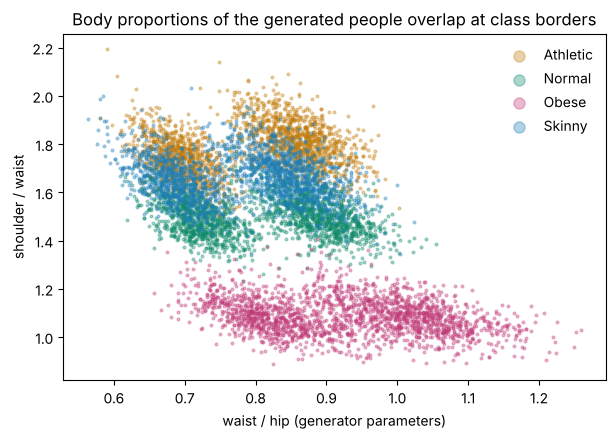

In [4]:
meta = pd.read_csv(config.DATA_DIR / 'train' / 'metadata.csv')
summary = meta.groupby('label')[['shoulder_waist_ratio', 'waist_hip_ratio']].describe().round(2)
display(summary)
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {'athletic': '#c47d0e', 'normal': '#0f8a6a', 'obese': '#c03a78', 'skinny': '#1f7fb8'}
for c in CLASSES:
    m = meta[meta.label == c]
    ax.scatter(m.waist_hip_ratio, m.shoulder_waist_ratio, s=4, alpha=.35, color=colors[c], label=CLASS_LABELS[c])
ax.set_xlabel('waist / hip (generator parameters)'); ax.set_ylabel('shoulder / waist'); ax.legend(markerscale=4, frameon=False)
ax.set_title('Body proportions of the generated people overlap at class borders'); plt.show()

## 3. From photo to silhouette

PhyVision classifies **shape**. Each image is reduced to the person's outline, which removes face, skin tone and clothing colour from the decision and makes the rendered training data transfer better to real photos. The pipeline is:

1. find the person (image alpha channel, then **rembg** `u2net_human_seg` if installed, otherwise **OpenCV GrabCut**),
2. clean the mask (keep the person, fill holes),
3. crop and scale the body into a 128 x 128 frame,
4. measure body width at 48 heights to build the shape profile.

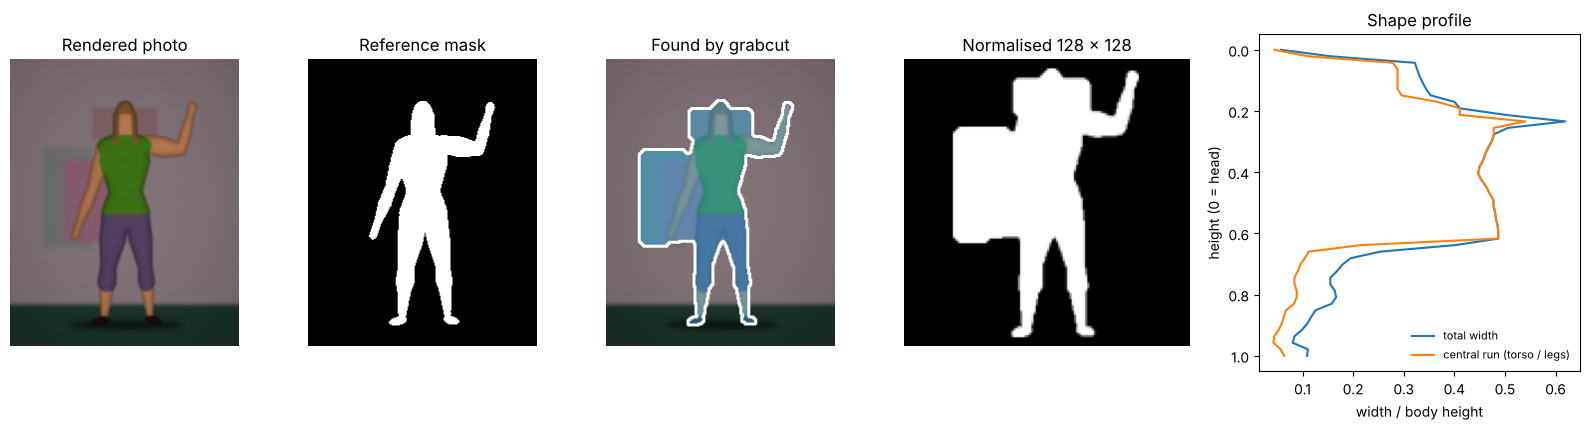

Generator parameters: {'label': 'athletic', 'sex': 'female', 'framing': 'full', 'visible': 1.0, 'arm_pose': np.str_('one_flex'), 'top': np.str_('tank'), 'shoulder_waist_ratio': 1.642, 'waist_hip_ratio': 0.684}
Measured from the GrabCut silhouette: {'shoulder_width_pct_height': 41.2, 'waist_width_pct_height': 44.7, 'hip_width_pct_height': 47.8, 'shoulder_to_waist': 0.92, 'waist_to_hip': 0.94, 'silhouette_fill': 0.471, 'aspect_w_h': 0.686, 'arms_separate': False, 'reliable': False}


In [5]:
from phyvision.synth import generate_person
from phyvision.silhouette import extract_mask, normalise, shape_profile, body_metrics, overlay

img, true_mask, params = generate_person('athletic', seed=2024)
gc_mask, method = extract_mask(img, 'grabcut')
sil = normalise(gc_mask); prof = shape_profile(gc_mask)

fig, ax = plt.subplots(1, 5, figsize=(16, 4.4), gridspec_kw={'width_ratios': [1, 1, 1, 1.25, 1.4]})
ax[0].imshow(img); ax[0].set_title('Rendered photo')
ax[1].imshow(true_mask, cmap='gray'); ax[1].set_title('Reference mask')
ax[2].imshow(overlay(img, gc_mask)); ax[2].set_title(f'Found by {method}')
ax[3].imshow(sil, cmap='gray'); ax[3].set_title('Normalised 128 x 128')
y = np.linspace(0, 1, 48)
ax[4].plot(prof[:48] / 4, y, label='total width'); ax[4].plot(prof[48:96] / 4, y, label='central run (torso / legs)')
ax[4].invert_yaxis(); ax[4].set_xlabel('width / body height'); ax[4].set_ylabel('height (0 = head)'); ax[4].legend(frameon=False, fontsize=8)
ax[4].set_title('Shape profile')
for a in ax[:4]: a.axis('off')
plt.tight_layout(); plt.show()
print('Generator parameters:', {k: params[k] for k in ['label', 'sex', 'framing', 'visible', 'arm_pose', 'top', 'shoulder_waist_ratio', 'waist_hip_ratio']})
print('Measured from the GrabCut silhouette:', body_metrics(gc_mask))

### Training augmentation that imitates segmentation mistakes

Real segmenters make errors. During training every mask is randomly flipped, eroded or dilated, given ragged edges, stray blobs and holes, slightly rotated, and sometimes has the feet cut off. The model learns to classify through those errors.

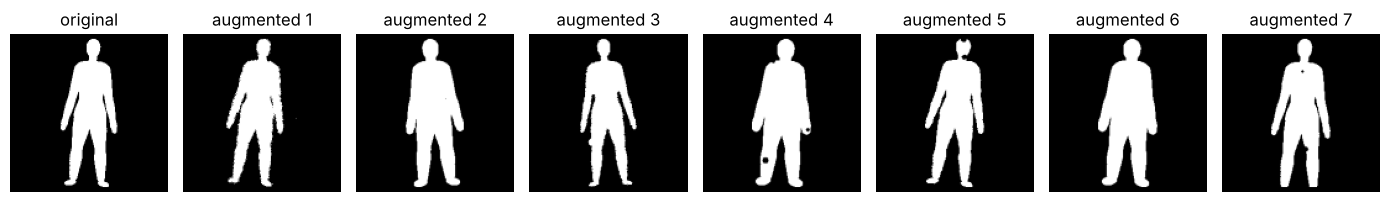

In [6]:
from phyvision.dataset import augment_mask
m = cv2.imread(str(sorted((config.DATA_DIR / 'train' / 'normal').glob('*_mask.png'))[5]), 0)
fig, ax = plt.subplots(1, 8, figsize=(14, 3.2))
ax[0].imshow(normalise(m), cmap='gray'); ax[0].set_title('original')
for k in range(1, 8):
    ax[k].imshow(normalise(augment_mask(m, np.random.default_rng(k))[0]), cmap='gray'); ax[k].set_title(f'augmented {k}')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 4. PhyNet

* **Silhouette branch:** ResNet-18 (single-channel stem, trained from scratch) turns the 128 x 128 silhouette into 512 features.
* **Profile branch:** an MLP turns the 100-number shape profile into 64 features.
* **Class head:** BatchNorm, Dropout 0.4, Linear 576 to 128, ReLU, Dropout 0.2, Linear 128 to 4.
* **Framing head:** Linear 576 to 64, ReLU, Linear 64 to 1, sigmoid: the fraction of the body visible in the photo (1.0 = head to feet). Learning it helps the classifier read cropped photos, and the app reports it.

Training runs in two stages:

1. **Shape (16 epochs).** Exact training masks with segmentation-error augmentation. AdamW, one-cycle cosine schedule, label smoothing 0.05, batch 64.
2. **Real segmenters (two rounds of 6 epochs).** Every training photo is cut out again from scratch, half by rembg and half by GrabCut, and PhyNet is fine-tuned on a 50/50 mix of exact and segmenter masks, so it learns the mistakes background removers make. Each round keeps the checkpoint with the best validation accuracy over both kinds of mask.
3. **Weight averaging.** The released model averages the weights of the two rounds' best checkpoints. It ties round 2 alone on validation and gives steadier predictions on a real photo (see the model card).

The test split is only used once, for the final report.

*AI assistance:* the training pipeline was developed with help from Claude, an AI model by Anthropic, for educational purposes.

In [7]:
from phyvision.model import PhyNet
net = PhyNet()
print(f'Parameters: {sum(p.numel() for p in net.parameters()):,}')
with torch.no_grad():
    logits, visible = net.eval()(torch.zeros(2, 1, 128, 128), torch.zeros(2, config.PROFILE_DIM))
    print('Class logits:', tuple(logits.shape), '| framing output:', tuple(visible.shape))

Parameters: 11,304,197
Class logits: (2, 4) | framing output: (2,)


In [8]:
if TRAIN:
    import subprocess
    from phyvision.train import main as train_main
    train_main(['--epochs', '16'])
    import shutil
    def masks(jobs):
        for method, split, start, count in jobs:
            subprocess.run([sys.executable, 'scripts/build_segmenter_masks.py', '--method', method, '--split', split,
                            '--start', str(start), '--count', str(count)], check=True)
    from phyvision.finetune import main as finetune_main
    masks([('rembg', 'train', 0, 500), ('grabcut', 'train', 500, 500), ('rembg', 'val', 0, 100), ('grabcut', 'val', 100, 100)])
    finetune_main(['--epochs', '6'])                                   # round 1
    shutil.copy(config.CHECKPOINT, config.MODELS_DIR / 'round1_best.pt')
    masks([('rembg', 'train', 1000, 500), ('grabcut', 'train', 1500, 500)])
    finetune_main(['--append', '--epochs', '6', '--lr', '3e-4', '--seed', '11'])  # round 2
    shutil.copy(config.CHECKPOINT, config.MODELS_DIR / 'round2_best.pt')
    subprocess.run([sys.executable, 'scripts/average_checkpoints.py', str(config.MODELS_DIR / 'round1_best.pt'),
                    str(config.MODELS_DIR / 'round2_best.pt'), '--out', str(config.CHECKPOINT)], check=True)

hist = json.loads((config.REPORTS_DIR / 'history.json').read_text())
display(pd.DataFrame(hist).set_index('epoch').round(4))
ft = json.loads((config.REPORTS_DIR / 'history_finetune.json').read_text())
print('Stage 2 fine-tuning (validation accuracy with exact masks / with segmenter masks):')
pd.DataFrame(ft).set_index('epoch')[['val_ref_acc', 'val_seg_acc']].round(4)

,train_loss,train_acc,val_loss,val_acc,val_framing_mae,lr,seconds
epoch,,,,,,,
1,1.1776,0.5784,0.9676,0.6780,0.0275,0.0008,259.5775
2,0.7485,0.7564,1.4097,0.5638,0.0243,0.0019,265.6623
3,0.6320,0.8255,1.0190,0.7422,0.0174,0.0020,269.1868
4,0.5547,0.8584,0.5438,0.8418,0.0124,0.0019,260.0820
5,0.5021,0.8832,0.5600,0.8602,0.0097,0.0018,259.8471
6,0.4581,0.9030,1.1223,0.6145,0.0100,0.0017,266.0120
7,0.4242,0.9184,0.3933,0.9242,0.0100,0.0015,262.9982
8,0.3926,0.9325,0.3763,0.9305,0.0081,0.0013,259.0221
9,0.3577,0.9480,0.4320,0.9035,0.0070,0.0010,251.8630


Stage 2 fine-tuning (validation accuracy with exact masks / with segmenter masks):


,val_ref_acc,val_seg_acc
epoch,,
0,0.9548,0.7272
1,0.9128,0.7685
2,0.9352,0.7997
3,0.9425,0.8285
4,0.9475,0.8473
5,0.9588,0.8623
6,0.9592,0.8598
7,0.9375,0.8273
8,0.9570,0.8373


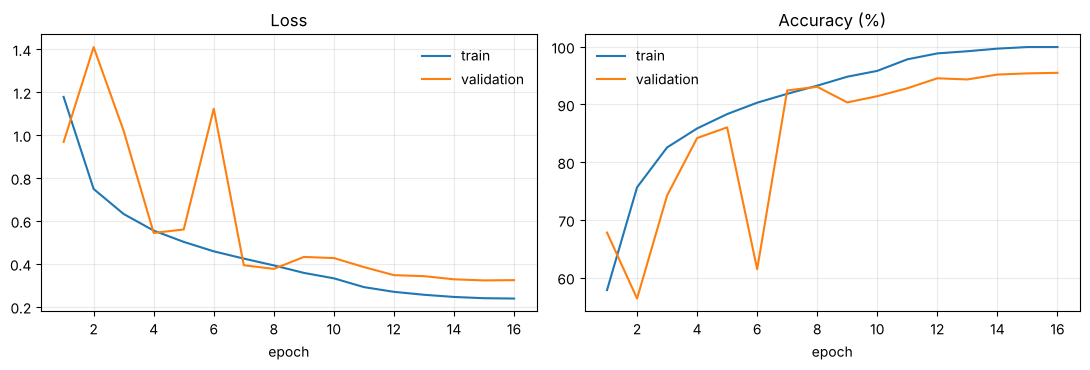

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ep = [h['epoch'] for h in hist]
ax[0].plot(ep, [h['train_loss'] for h in hist], label='train'); ax[0].plot(ep, [h['val_loss'] for h in hist], label='validation'); ax[0].set_title('Loss')
ax[1].plot(ep, [100 * h['train_acc'] for h in hist], label='train'); ax[1].plot(ep, [100 * h['val_acc'] for h in hist], label='validation'); ax[1].set_title('Accuracy (%)')
for a in ax: a.set_xlabel('epoch'); a.legend(frameon=False); a.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 5. Evaluation on the held-out test set

Two numbers are reported:

* **Reference masks:** all 4,000 test people, using their exact masks. This measures the classifier.
* **Photo pipeline:** 400 test JPEGs (100 per class) segmented from scratch, exactly as an uploaded photo would be, once with rembg and once with the offline GrabCut fallback. These measure the end-to-end system.

In [10]:
if TRAIN or not config.METRICS_JSON.exists():
    from phyvision.evaluate import main as eval_main
    eval_main([])
M = json.loads(config.METRICS_JSON.read_text())
for key, name in [('reference_masks', 'Reference masks'), ('photo_pipeline_rembg', 'Photo pipeline (rembg)'),
                  ('photo_pipeline_grabcut', 'Photo pipeline (GrabCut)')]:
    r = M.get(key)
    if not r: continue
    print(f"{name:26s} accuracy {100 * r['accuracy']:.2f}%   macro-F1 {r['macro_f1']:.3f}   n={r['n']}")
pd.DataFrame(M['reference_masks']['per_class']).T.round(3)

Reference masks            accuracy 97.00%   macro-F1 0.970   n=4000
Photo pipeline (rembg)     accuracy 88.00%   macro-F1 0.880   n=600
Photo pipeline (GrabCut)   accuracy 81.33%   macro-F1 0.813   n=600


,precision,recall,f1-score,support
athletic,0.983,0.987,0.985,1000.0
normal,0.936,0.946,0.941,1000.0
obese,1.000,0.998,0.999,1000.0
skinny,0.961,0.949,0.955,1000.0


In [11]:
# Accuracy by photo framing (how much of the body is in the photo)
rows = {}
for key, name in [('reference_masks', 'reference masks'), ('photo_pipeline_rembg', 'rembg'), ('photo_pipeline_grabcut', 'GrabCut')]:
    bf = (M.get(key) or {}).get('by_framing', {})
    rows[name] = {f: f"{100 * v['accuracy']:.1f}% (n={v['n']})" for f, v in bf.items()}
pd.DataFrame(rows).rename(index={'full': 'head to feet', 'knees': 'head to knees', 'thigh': 'head to mid-thigh', 'waist': 'waist up'})

,reference masks,rembg,GrabCut
head to feet,97.7% (n=2042),88.2% (n=305),80.0% (n=305)
head to knees,97.4% (n=575),95.2% (n=83),81.9% (n=83)
head to mid-thigh,95.2% (n=774),86.7% (n=113),79.6% (n=113)
waist up,96.4% (n=609),82.8% (n=99),86.9% (n=99)


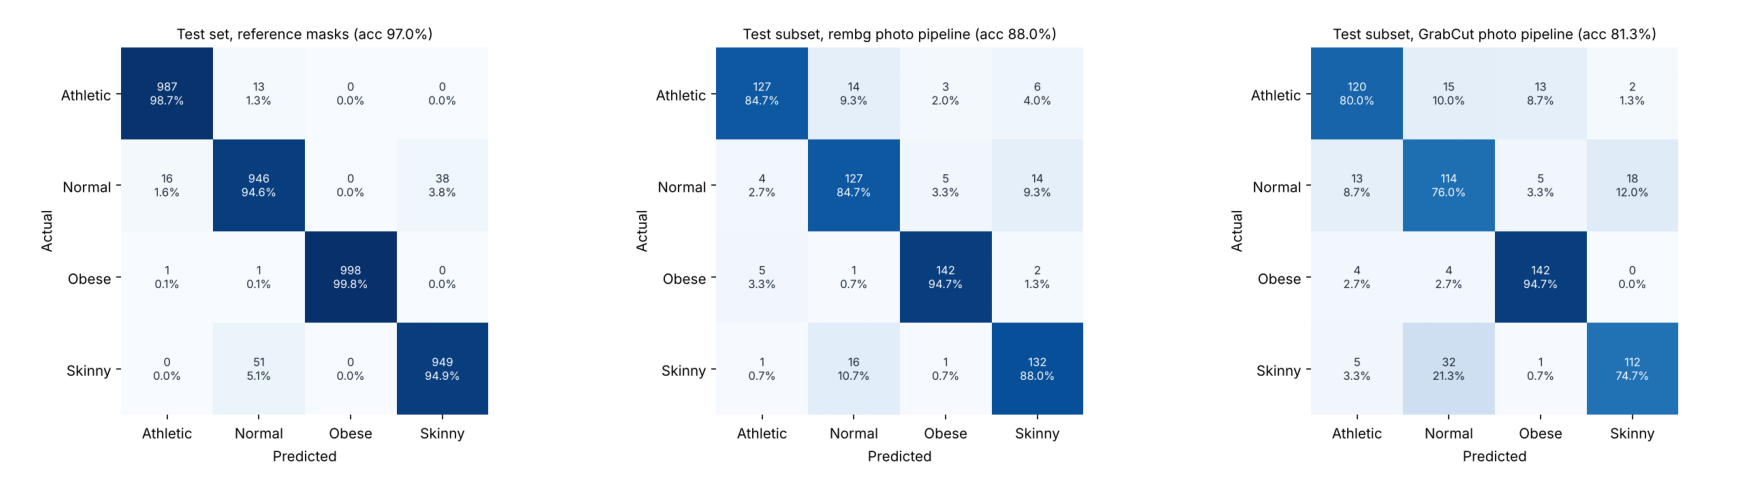

In [12]:
figs = [f for f in ['confusion_matrix.png', 'confusion_matrix_rembg_pipeline.png', 'confusion_matrix_photo_pipeline.png'] if (config.REPORTS_DIR / f).exists()]
fig, ax = plt.subplots(1, len(figs), figsize=(6 * len(figs), 5))
for a, f in zip(ax, figs):
    a.imshow(plt.imread(config.REPORTS_DIR / f)); a.axis('off')
plt.tight_layout(); plt.show()

## 6. Meet the demo people

Eight fictional, computer-rendered people ship with the project for testing. They are not photos of real individuals.

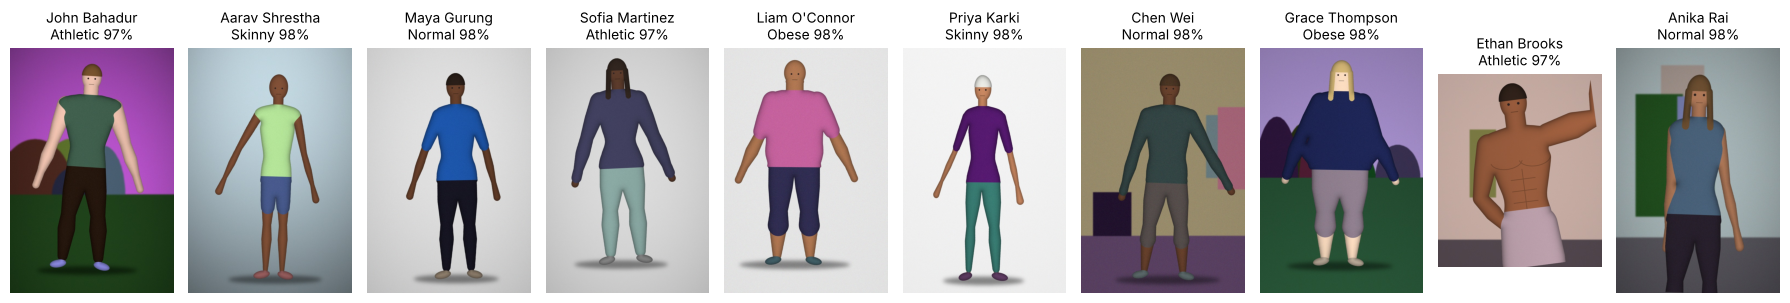

In [13]:
from phyvision.inference import Predictor
predictor = Predictor()
demos = json.loads((config.DEMO_DIR / 'demos.json').read_text())
fig, ax = plt.subplots(1, len(demos), figsize=(18, 5.2))
for a, d in zip(ax, demos):
    r = predictor.predict_file(config.WEB_DIR / d['image'], config.WEB_DIR / d['mask'])
    a.imshow(cv2.cvtColor(cv2.imread(str(config.WEB_DIR / d['image'])), cv2.COLOR_BGR2RGB)); a.axis('off')
    a.set_title(f"{d['name']}\n{r['label_display']} {100 * r['confidence']:.0f}%", fontsize=10)
plt.tight_layout(); plt.show()

## 7. Classify your own photo and get a fitness guide

Set `MY_IMAGE` to a path (in Colab, upload a file to the session first). rembg is used automatically when installed (it is in `requirements.txt`) and gives much better cut-outs than GrabCut; its model (about 170 MB) downloads on first use. Follow the photo guide (`web/photo-guide.html`): a portrait photo (about 2:3 or 3:4) of one person standing and facing the camera, head to feet in frame filling 75-95% of the height, arms slightly away from the body, fitted clothing, plain background.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


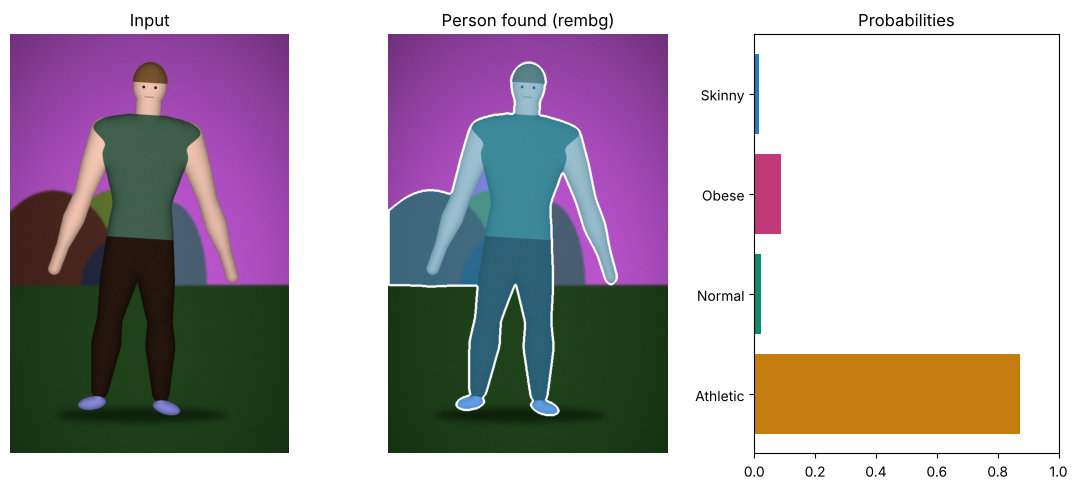

Prediction: Athletic (87.4%) | proportions: {'shoulder_width_pct_height': 31.8, 'waist_width_pct_height': 29.4, 'hip_width_pct_height': 46.4, 'shoulder_to_waist': 1.08, 'waist_to_hip': 0.63, 'silhouette_fill': 0.425, 'aspect_w_h': 0.648, 'arms_separate': False, 'reliable': False}
Framing: Head to feet (about 100% of the body visible)
Photo check:
  [ok  ] Resolution: 600 x 900 px.
  [ok  ] Orientation: Portrait, width:height 0.67.
  [ok  ] One person: One person detected.
  [ok  ] Background: Person separated from the background.
  [ok  ] Person size: The person fills 84% of the photo height.
  [ok  ] Head in frame: Head fully visible.
  [warn] Centred: Part of the body touches the side of the photo. Keep arms and shoulders inside the frame.
  [ok  ] Framing: Full body visible, head to feet. This is the most reliable framing.


In [14]:
from phyvision.guides import guide_for, load_guides

MY_IMAGE = config.DEMO_DIR / 'john_bahadur.jpg'   # change me
r = predictor.predict_file(MY_IMAGE)                 # no reference mask: real segmentation is used

fig, ax = plt.subplots(1, 3, figsize=(11, 5))
ax[0].imshow(r['_rgb']); ax[0].set_title('Input')
ax[1].imshow(overlay(r['_rgb'], r['_mask'])); ax[1].set_title(f"Person found ({r['segmentation']})")
ax[2].barh([CLASS_LABELS[c] for c in CLASSES], [r['probabilities'][c] for c in CLASSES], color=['#c47d0e', '#0f8a6a', '#c03a78', '#1f7fb8'])
ax[2].set_xlim(0, 1); ax[2].set_title('Probabilities')
for a in ax[:2]: a.axis('off')
plt.tight_layout(); plt.show()
print(f"Prediction: {r['label_display']} ({100 * r['confidence']:.1f}%)", '| proportions:', r['metrics'])
print(f"Framing: {r['framing']['label']} (about {100 * r['framing']['visible']:.0f}% of the body visible)")
print('Photo check:')
for c in r['checks']: print(f"  [{c['status']:4s}] {c['name']}: {c['detail']}")

In [15]:
def show_guide(label):
    g = guide_for(label); t = g['training']
    lines = [f"### {g['title']} fitness guide: {g['tagline']}", g['summary'], '**Goals**'] + [f'- {x}' for x in g['goals']]
    lines += ['**Training focus.** ' + t['focus'], '', '| Day | Session |', '|---|---|'] + [f"| {d['day']} | {d['session']} |" for d in t['weekly_plan']]
    lines += ['', '**Key exercises:** ' + ', '.join(t['key_exercises']), '', '**Nutrition**'] + [f'- {x}' for x in g['nutrition']]
    lines += ['**Lifestyle**'] + [f'- {x}' for x in g['lifestyle']] + ['**Stay safe**'] + [f'- {x}' for x in g['cautions']]
    lines += ['', '*' + load_guides()['disclaimer'] + '*']
    display(Markdown('\n'.join(lines)))

show_guide(r['label'])

### Athletic fitness guide: Muscular build with a strong shoulder-to-waist taper
Your silhouette shows broad shoulders relative to the waist and well-developed arms and legs, the classic V-taper of a trained body. The focus now is smart programming: keep progressing without burning out, balance strength with mobility and conditioning, and protect your joints.
**Goals**
- Keep making progress with structured, periodised training
- Balance strength with mobility, conditioning and injury prevention
- Fuel performance and recovery properly
- Maintain healthy body composition year-round, not just for a peak
**Training focus.** 4 to 5 structured sessions a week (for example an upper/lower or push/pull/legs split), 1 to 2 conditioning sessions, and regular deload weeks.

| Day | Session |
|---|---|
| Mon | Upper strength: heavy press and pull, 4 to 6 reps |
| Tue | Lower strength: squat, deadlift variation, single-leg work |
| Wed | Conditioning and mobility: zone-2 cardio 30 to 45 minutes plus hips, thoracic spine and shoulders |
| Thu | Upper hypertrophy: 8 to 15 reps, more volume |
| Fri | Lower hypertrophy and posterior chain |
| Sat | Sport, sprints or intervals |
| Sun | Rest |

**Key exercises:** Back or front squat, Deadlift or trap-bar deadlift, Bench and incline press, Weighted pull-ups, Overhead press, Bulgarian split squat, Face pulls and rear-delt work, Loaded carries, Zone-2 cardio

**Nutrition**
- Eat to your goal: maintenance to stay where you are, a small surplus (about 200 to 300 kcal) to keep gaining muscle, a small deficit to lean out.
- Protein about 1.6 to 2.2 g per kg of body weight per day, including 20 to 40 g around training.
- Carbohydrates fuel hard training. Put most of them around your sessions.
- Include omega-3 sources (oily fish, walnuts, flax), fruit and vegetables for recovery.
- Hydrate well, and replace sodium if you sweat heavily.
**Lifestyle**
- Sleep 8 hours or more during heavy training blocks.
- Schedule a deload every 4 to 6 weeks.
- Do 10 minutes of mobility work most days.
- Watch for overtraining signs: poor sleep, persistent soreness, falling performance, low mood.
**Stay safe**
- Avoid supplements or substances that are not third-party tested. Anabolic steroids carry serious health risks.
- Get persistent joint pain assessed rather than training through it.

*PhyVision estimates body shape from a 2-D silhouette. It does not measure body fat, weight, muscle mass or health, and it is not a medical device. These guides are general fitness education. Talk to a doctor or registered dietitian before starting a new diet or exercise programme, especially if you have a medical condition, are pregnant, are under 18, or are recovering from injury.*

## 8. Training-image integrity check

Carried over from v4.0: every training image is fingerprinted with MD5. If someone uploads a training image, the result is flagged as memory rather than generalisation.

In [16]:
train_img = sorted((config.DATA_DIR / 'train' / 'skinny').glob('*.jpg'))[0]
test_img = sorted((config.DATA_DIR / 'test' / 'skinny').glob('*.jpg'))[0]
for p in (train_img, test_img):
    res = predictor.predict_file(p)
    print(f"{p.parent.parent.name:5s} {p.name:28s} -> {res['label']:8s} training-set match: {res['training_image_match']}")

train skinny_train_00000.jpg       -> skinny   training-set match: skinny


test  skinny_test_00000.jpg        -> skinny   training-set match: None


## 9. Limitations and next steps

* The model is trained only on rendered people. Silhouettes narrow the gap to real photos, but accuracy on real photos will be lower than the test numbers above and depends heavily on segmentation quality. Fine-tuning on a consented, labelled set of real photos is the most valuable next step (add them under `data/phyvision_dataset/<split>/<class>/` with masks and retrain).
* A single 2-D outline cannot see body fat versus muscle directly. Loose clothing, side-on poses and partial bodies reduce reliability, and the photo check flags these.
* Body type is a coarse description, not a health measurement. The guides are general education and include safety notes.
* Next steps: real-photo fine-tuning, pose keypoints (for side views), and depth cues.

*PhyVision was created and authored by Swayam Shakya.*